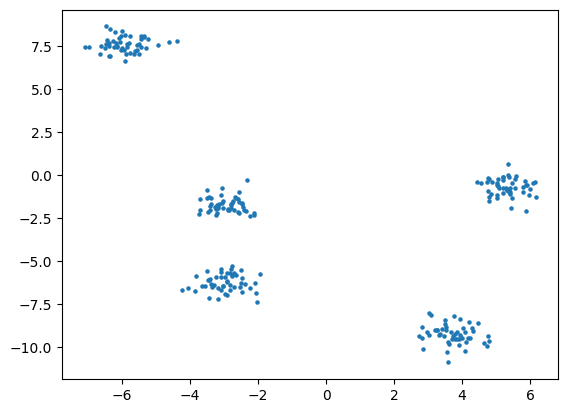

In [90]:
from sklearn.datasets import make_blobs
import matplotlib.pyplot as plt

k = 5

data, _ = make_blobs(n_samples=250, centers=k, cluster_std = 0.5)
plt.scatter(data[:, 0], data[:, 1], s = 5)

In [91]:
import numpy as np

def get_dist_matrix(data):
  # 모든 데이터들과 데이터들 간의 거리 행렬을 반환함
  s = np.sum(data**2, axis=1)
  dist_sq = s[:, np.newaxis] + s[np.newaxis, :] - 2 * np.dot(data, data.T)
  return np.sqrt(np.maximum(dist_sq, 0))

def diana_split(indices, full_dist_matrix):
  if len(indices) <= 1:
    return indices, []

  Ci = list(indices)
  Cj = []

  # 가장 먼 애를 찾음. 그 데이터는 분리됨.
  sub_dist = full_dist_matrix[np.ix_(Ci, Ci)]
  avg_dists = np.sum(sub_dist, axis=1) / (len(Ci) - 1)
  splinter_idx = Ci[np.argmax(avg_dists)]

  Cj.append(splinter_idx)
  Ci.remove(splinter_idx)

  while True:
      max_diff = -np.inf
      target = -1
      for item in Ci:
          at_i = np.mean([full_dist_matrix[item][other] for other in Ci if other != item]) if len(Ci) > 1 else 0
          at_j = np.mean([full_dist_matrix[item][other] for other in Cj])
          if (at_i - at_j) > max_diff:
              max_diff = at_i - at_j
              target = item

      if max_diff > 0:
          Cj.append(target)
          Ci.remove(target)
      else:
        break
  return Ci, Cj

def get_diameter(indices, full_dist_matrix):
  if len(indices) <= 1:
    return 0
  sub_dist = full_dist_matrix[np.ix_(indices, indices)]
  return np.max(sub_dist)

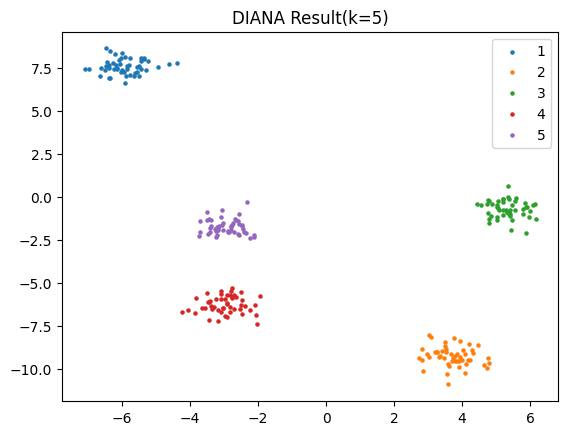

In [93]:
import matplotlib.pyplot as plt

full_dist_matrix = get_dist_matrix(data)
clusters = [list(range(len(data)))] # 처음엔 모두가 한 팀, cluster에는 각 데이터의 인덱스가 리스트 형태로 들어감

while len(clusters) < k:
  # diameter이 가장 큰 군집 찾기
  diameters = [get_diameter(c, full_dist_matrix) for c in clusters]
  target_cluster_idx = np.argmax(diameters)

  if diameters[target_cluster_idx] == 0:
    break # 더 이상 쪼갤 게 없음

  # 해당 군집 쪼개기
  to_split = clusters.pop(target_cluster_idx)
  c1, c2 = diana_split(to_split, full_dist_matrix)

  clusters.append(c1)
  clusters.append(c2)

# 결과 시각화
for i, cluster in enumerate(clusters):
  plt.scatter(data[cluster, 0], data[cluster, 1], label = i+1, s = 5)
  plt.title(f"DIANA Result(k={k})")
plt.legend()
plt.show()